# 05 Weighting an Opt-In Online Poll

**Setting:** an online opt-in health survey estimating the share of
adults who got a flu shot this season. Opt-in panels skew young and
college-educated, and both traits predict vaccination.
**Methods:** post-stratification, raking (iterative proportional
fitting) with and without trimming, propensity pseudo-weights against a
reference sample, Kish design effects, Taylor-linearization and
delete-a-group jackknife standard errors.
**Ground truth:** a synthetic population of 200,000 adults (the
"census") with a known vaccination rate. Each poll is drawn from it with
a known selection mechanism.

Two scenarios:
1. **Selection on observables:** who joins depends on age, education,
   region and sex. Weighting on those variables should work.
2. **Selection on the outcome:** people who got the shot are more
   interested in a health survey. No demographic weight can fix that.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_root = pathlib.Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root / "src"))
FIG_DIR = _root / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
# Categorical slots (validated palette), plus ink for the known truth
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#8a8984"

In [2]:
from surveyhub.simulate import make_population, opt_in_sample, AGE, EDU
from surveyhub.weighting import (rake, poststratify, pseudo_weights, dummies,
                                 weighted_mean, kish_deff, effective_n,
                                 linearized_se, jackknife)

pop = make_population(200_000, seed=51)
cov = pop.covariates()
targets = {v: pop.margins(v) for v in cov}
print(f"population: N = {pop.N:,}, true vaccination rate = {pop.truth:.3f}")

population: N = 200,000, true vaccination rate = 0.350


## 1. One poll, up close

In [3]:
idx = opt_in_sample(pop, 1500, seed=52)
y = pop.y[idx]
m = {v: cov[v][idx] for v in cov}
print(f"respondents: {len(idx)}\n")
print(f"{'group':<14s} {'population':>11s} {'poll':>7s}")
for v, names in (("age", AGE), ("edu", EDU)):
    for lev, name in enumerate(names):
        print(f"{name:<14s} {np.mean(cov[v] == lev):11.1%} {np.mean(m[v] == lev):7.1%}")

respondents: 1427

group           population    poll
18-29                21.0%   39.7%
30-44                25.0%   32.0%
45-64                33.1%   21.7%
65+                  20.9%    6.7%
HS or less           37.6%   11.2%
Some college         28.0%   25.6%
BA+                  34.4%   63.1%


In [4]:
cells_pop = pop.age * 3 + pop.edu
w_ps = poststratify(cells_pop[idx], np.bincount(cells_pop, minlength=12).astype(float))
r = rake(m, targets)
rt = rake(m, targets, trim=(0.3, 3.0))
rng = np.random.default_rng(53)
ref = rng.choice(pop.N, 2000, replace=False)
w_pw = pseudo_weights(dummies(m), dummies({v: cov[v][ref] for v in cov}),
                      np.full(2000, pop.N / 2000))
print(f"raking converged in {r.n_iter} sweeps, worst margin error {r.max_margin_error:.1e}\n")
print(f"{'method':<26s} {'estimate':>9s} {'error':>7s} {'deff':>6s} {'eff n':>7s} {'SE (lin)':>9s}")
print(f"{'unweighted':<26s} {y.mean():9.3f} {y.mean() - pop.truth:+7.3f} {1:6.2f} {len(y):7.0f} "
      f"{linearized_se(y, np.ones(len(y))):9.4f}")
for name, w in [("post-strat (age x edu)", w_ps), ("raked (4 margins)", r.weights),
                ("raked + trimmed", rt.weights), ("propensity pseudo-weights", w_pw)]:
    e = weighted_mean(y, w)
    print(f"{name:<26s} {e:9.3f} {e - pop.truth:+7.3f} {kish_deff(w):6.2f} {effective_n(w):7.0f} "
          f"{linearized_se(y, w):9.4f}")

raking converged in 8 sweeps, worst margin error 1.0e-11

method                      estimate   error   deff   eff n  SE (lin)
unweighted                     0.328  -0.022   1.00    1427    0.0124
post-strat (age x edu)         0.350  +0.001   2.52     566    0.0202
raked (4 margins)              0.348  -0.002   2.50     572    0.0201
raked + trimmed                0.352  +0.003   2.28     625    0.0190
propensity pseudo-weights      0.355  +0.005   2.68     532    0.0210


Weighting moves the estimate toward the truth and costs precision: the
design effect from unequal weights shrinks 1,500 respondents to an
effective sample of a few hundred. Trimming extreme weights buys some of
that back at the cost of a little bias.

The jackknife re-runs the raking on each replicate, so its standard
error includes the variability of the weighting step itself.

In [5]:
def raked_estimate(keep):
    w = rake({v: m[v][keep] for v in m}, targets).weights
    return weighted_mean(y[keep], w)

jk = jackknife(raked_estimate, len(y), n_groups=20, seed=54)
print(f"raked estimate {jk.estimate:.3f}: linearized SE {linearized_se(y, r.weights):.4f}, "
      f"jackknife SE {jk.se:.4f}")

raked estimate 0.348: linearized SE 0.0201, jackknife SE 0.0162


## 2. Repeat the poll 200 times, in both scenarios

For each method, record bias, the spread of estimates, and whether the
95% CI covers the truth. For raking, compare linearized and jackknife
CIs.

In [6]:
def run(outcome_effect, R=200, seed=0):
    rng = np.random.default_rng(seed)
    out = {k: [] for k in ["unweighted", "post-stratified", "raked", "raked + trimmed", "pseudo-weights"]}
    cover = {k: [] for k in out}
    cover_jk = []
    for _ in range(R):
        idx = opt_in_sample(pop, 1500, outcome_effect=outcome_effect, seed=rng.integers(1 << 31))
        y = pop.y[idx]
        m = {v: cov[v][idx] for v in cov}
        ref = rng.choice(pop.N, 2000, replace=False)
        ws = {
            "unweighted": np.ones(len(y)),
            "post-stratified": poststratify(cells_pop[idx], np.bincount(cells_pop, minlength=12).astype(float)),
            "raked": rake(m, targets).weights,
            "raked + trimmed": rake(m, targets, trim=(0.3, 3.0)).weights,
            "pseudo-weights": pseudo_weights(dummies(m), dummies({v: cov[v][ref] for v in cov}),
                                             np.full(2000, pop.N / 2000)),
        }
        for k, w in ws.items():
            e, se = weighted_mean(y, w), linearized_se(y, w)
            out[k].append(e)
            cover[k].append(abs(e - pop.truth) < 1.96 * se)
        jk = jackknife(lambda keep: weighted_mean(y[keep], rake({v: m[v][keep] for v in m}, targets).weights),
                       len(y), n_groups=20, seed=rng.integers(1 << 31))
        cover_jk.append(abs(jk.estimate - pop.truth) < 1.96 * jk.se)
    return ({k: np.array(v) for k, v in out.items()},
            {k: np.mean(v) for k, v in cover.items()}, np.mean(cover_jk))

sims = {}
for label, eff in [("Selection on observables", 0.0), ("Selection on the outcome", 0.8)]:
    est, cov_rate, cov_jk = run(eff, seed=55 if eff == 0 else 56)
    sims[label] = (est, cov_rate, cov_jk)
    print(label)
    print(f"  {'method':<18s} {'bias':>7s} {'SD':>6s} {'RMSE':>6s} {'95% CI coverage':>16s}")
    for k, e in est.items():
        print(f"  {k:<18s} {e.mean() - pop.truth:+7.3f} {e.std():6.3f} "
              f"{np.sqrt(np.mean((e - pop.truth) ** 2)):6.3f} {cov_rate[k]:16.1%}")
    print(f"  raked with jackknife CI: coverage {cov_jk:.1%}\n")

Selection on observables
  method                bias     SD   RMSE  95% CI coverage
  unweighted          -0.034  0.012  0.036            20.5%
  post-stratified     +0.002  0.018  0.018            95.5%
  raked               -0.000  0.018  0.018            96.0%
  raked + trimmed     +0.002  0.017  0.017            97.5%
  pseudo-weights      -0.002  0.018  0.018            94.5%
  raked with jackknife CI: coverage 94.5%

Selection on the outcome
  method                bias     SD   RMSE  95% CI coverage
  unweighted          +0.155  0.013  0.156             0.0%
  post-stratified     +0.174  0.019  0.175             0.0%
  raked               +0.171  0.019  0.172             0.0%
  raked + trimmed     +0.170  0.018  0.170             0.0%
  pseudo-weights      +0.171  0.019  0.172             0.0%
  raked with jackknife CI: coverage 0.0%



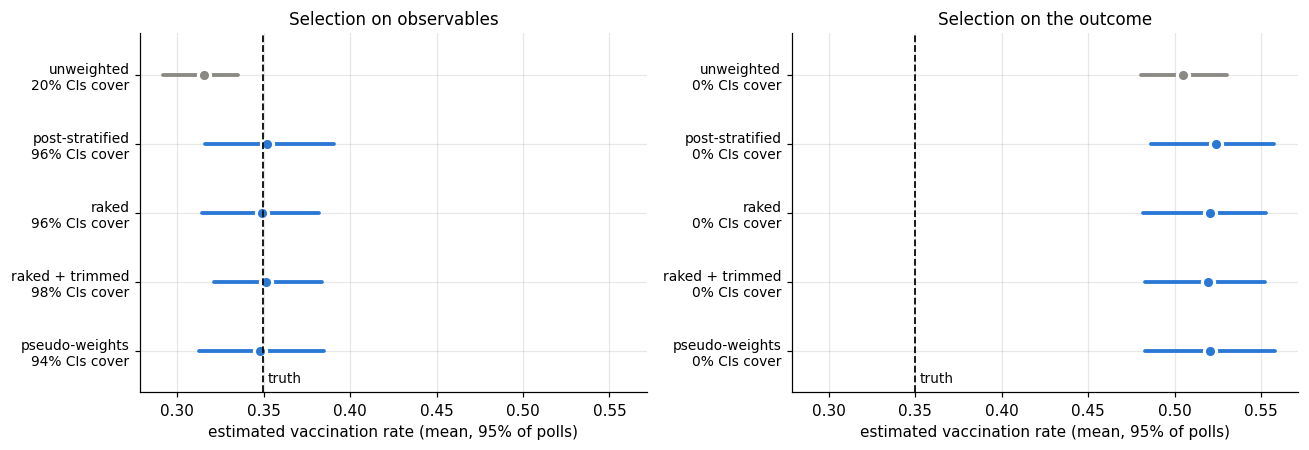

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ax, (label, (est, cov_rate, cov_jk)) in zip(axes, sims.items()):
    names = list(est)
    for i, k in enumerate(names):
        lo, hi = np.percentile(est[k], [2.5, 97.5])
        col = MUTED if k == "unweighted" else BLUE
        ax.plot([lo, hi], [i, i], color=col, lw=2.5, solid_capstyle="round")
        ax.plot(est[k].mean(), i, "o", color=col, ms=8, markeredgecolor="white", markeredgewidth=2)
    ax.axvline(pop.truth, color=INK, ls="--", lw=1.2)
    ax.text(pop.truth + 0.003, len(names) - 0.55, "truth", fontsize=9, color=INK)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels([f"{k}\n{cov_rate[k]:.0%} CIs cover" for k in names], fontsize=9)
    ax.set_ylim(len(names) - 0.4, -0.6)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("estimated vaccination rate (mean, 95% of polls)")
fig.tight_layout()
fig.savefig(FIG_DIR / "weighting_poll.png", dpi=150, bbox_inches="tight")
plt.show()

## Takeaways

* When selection depends only on variables with known population totals,
  raking, post-stratification, and propensity weights all remove the
  bias of the raw opt-in sample, and their CIs cover close to 95%.
* Weighting is not free: design effects of 2 or more halve the
  effective sample size. Trimming trades a little bias for precision.
* When selection depends on the outcome itself, every demographic weight
  leaves the bias in place (here it even grows a little, because the
  weights up-weight the groups whose few volunteers are the most
  self-selected), and the CIs become confidently wrong. No amount of weighting can test for this from inside the
  sample; it calls for a benchmark question with a known answer, a
  probability sample, or a sensitivity analysis.